<a href="https://colab.research.google.com/github/mustafasemary2010-coder/StreamLite-Applications-_Part_2/blob/main/notebook68d9ad85de.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [7]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

mustafasemary_dataset_path = kagglehub.dataset_download('mustafasemary/dataset')

print('Data source import complete.')


100%|██████████| 183k/183k [00:00<00:00, 43.4MB/s]

Extracting files...
Data source import complete.


In [34]:
# 0.0  Install / import
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(f"OpenCV version : {cv2.__version__}")
print(f"NumPy version  : {np.__version__}")

# Helper: show one or more images side-by-side with matplotlib
# (cv2.imshow() does not work in Jupyter / Colab)
def show(images, titles=None, cmap=None, figsize=None):
    """Display a list of images side-by-side."""
    if not isinstance(images, (list, tuple)):
        images = [images]
    n = len(images)
    figsize = figsize or (5 * n, 4)
    titles  = titles or [''] * n
    fig, axes = plt.subplots(1, n, figsize=figsize)
    if n == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print("show() helper ready.")

OpenCV version : 5.0.0
NumPy version  : 2.4.6
show() helper ready.


Shape  : (182, 276, 3)   (H x W x C)
Dtype  : uint8
Pixel range : 0 – 255


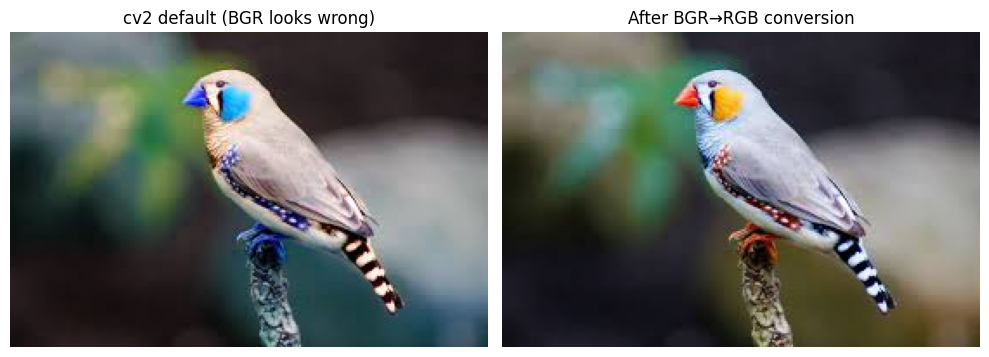

Saved to output_saved.jpg


In [22]:
# ── Read an image from disk ──────────────────────────────────────────────────
# IMPORTANT: OpenCV reads images in BGR order, NOT RGB.
#            matplotlib expects RGB — always convert before displaying.

img_bgr = cv2.imread('/bird2.jpeg')          # shape: (H, W, 3), dtype: uint8

if img_bgr is None:
    # Create a synthetic 300×400 test image if no file exists
    img_bgr = np.zeros((300, 400, 3), dtype='uint8')
    img_bgr[:, :, 0] = 180   # Blue channel
    img_bgr[50:250, 50:350, 1] = 120   # Green rectangle
    img_bgr[100:200, 150:250, 2] = 240  # Red square
    print("No 'sample.jpg' found — using synthetic image.")

# Convert BGR → RGB for display
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

print(f"Shape  : {img_bgr.shape}   (H x W x C)")
print(f"Dtype  : {img_bgr.dtype}")
print(f"Pixel range : {img_bgr.min()} – {img_bgr.max()}")

show([img_bgr, img_rgb],
     ['cv2 default (BGR looks wrong)', 'After BGR→RGB conversion'],
     figsize=(10, 4))

# ── Save an image to disk ────────────────────────────────────────────────────
cv2.imwrite('output_saved.jpg', img_bgr)   # pass BGR; cv2 handles encoding
print("Saved to output_saved.jpg")

**Image color space conversion**#

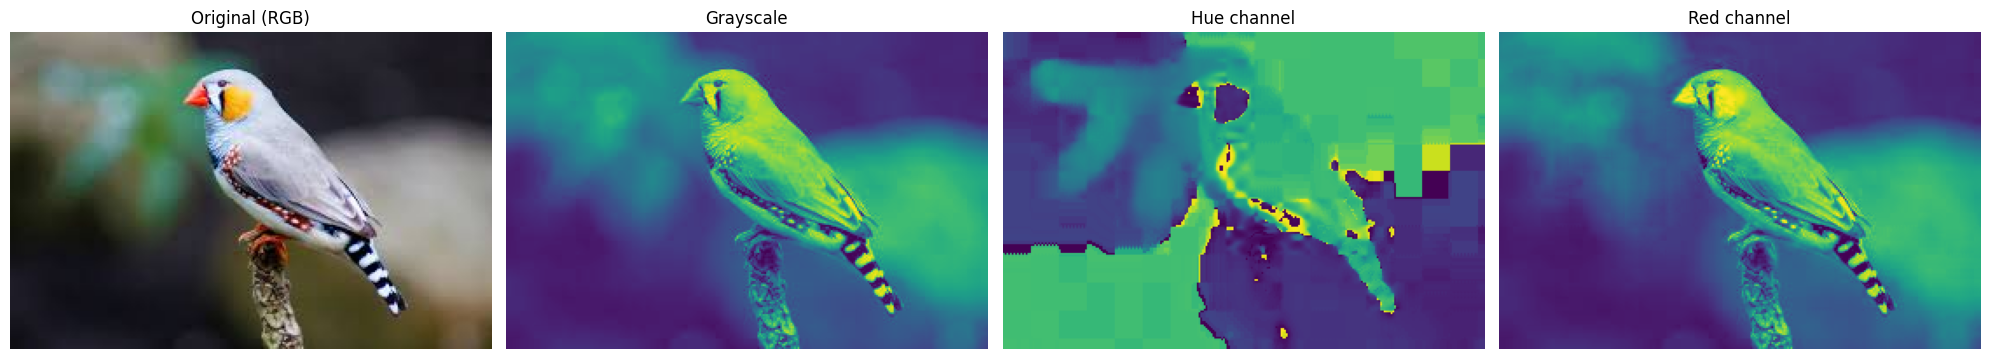

Grayscale shape : (182, 276)
HSV       shape : (182, 276, 3)


In [23]:
# ── Grayscale ────────────────────────────────────────────────────────────────
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
# shape becomes (H, W) — no channel dimension

# ── HSV  (Hue-Saturation-Value) ───────────────────────────────────────────────
# Useful for color-based segmentation (e.g., detect all red pixels)
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# ── Split and merge individual channels ──────────────────────────────────────
b, g, r = cv2.split(img_bgr)   # three (H, W) arrays
merged  = cv2.merge([b, g, r]) # rebuild the 3-channel image

show(
    [img_rgb, gray, hsv[:,:,0], r],
    ['Original (RGB)', 'Grayscale', 'Hue channel', 'Red channel'],

)

print(f"Grayscale shape : {gray.shape}")
print(f"HSV       shape : {hsv.shape}")

**Resizing and croping**#

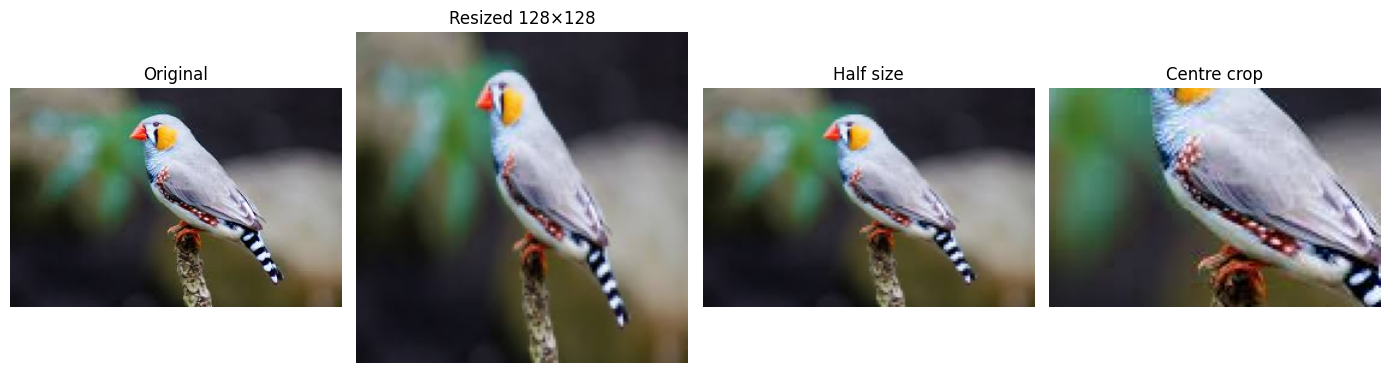

Interpolation options:
  INTER_AREA   — best for shrinking (downscale)
  INTER_CUBIC  — best for enlarging (upscale)
  INTER_LINEAR — fast, decent quality (default)


In [24]:
#Resizing and Croping
# ── Resize to fixed dimensions ───────────────────────────────────────────────
# cv2.resize takes (width, height) — opposite of NumPy's (rows=height, cols=width)
small  = cv2.resize(img_bgr, (128, 128), interpolation=cv2.INTER_AREA)
large  = cv2.resize(img_bgr, (512, 512), interpolation=cv2.INTER_CUBIC)

# ── Resize by scale factor ───────────────────────────────────────────────────
half  = cv2.resize(img_bgr, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

# ── Crop using NumPy slicing ─────────────────────────────────────────────────
# array[y_start:y_end, x_start:x_end]  ← rows first, then columns
h, w = img_bgr.shape[:2]
crop = img_bgr[h//4 : 3*h//4,  w//4 : 3*w//4]   # centre 50% region

show(
    [cv2.cvtColor(x, cv2.COLOR_BGR2RGB) for x in [img_bgr, small, half, crop]],
    ['Original', f'Resized 128×128', 'Half size', 'Centre crop'],
    figsize=(14, 4)
)

print(f"Interpolation options:")
print("  INTER_AREA   — best for shrinking (downscale)")
print("  INTER_CUBIC  — best for enlarging (upscale)")
print("  INTER_LINEAR — fast, decent quality (default)")

**Drawing shapes and text**#

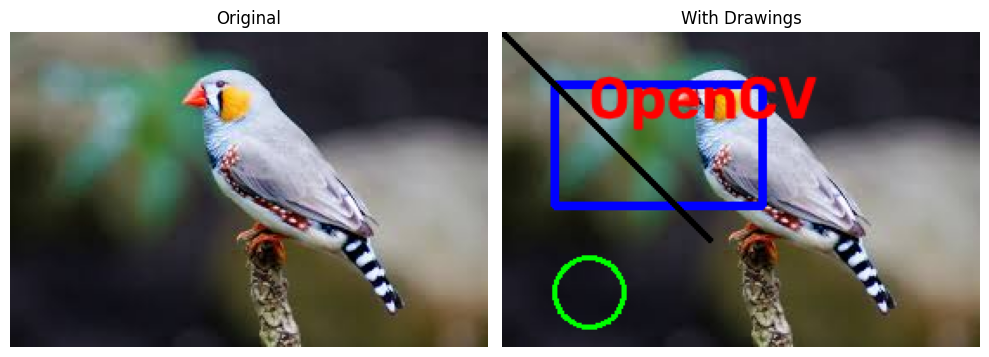

In [25]:
# Drawing on Images
canvas = img_rgb.copy()   # work on a copy so original is untouched

# ── Rectangle ────────────────────────────────────────────────────────────────
cv2.rectangle(canvas,
              pt1=(30, 30),       # top-left corner (x, y)
              pt2=(150, 100),     # bottom-right corner
              color=(0, 0, 255),  # RGB when image is RGB
              thickness=3)

# ── Circle ───────────────────────────────────────────────────────────────────
cv2.circle(canvas,
           center=(50, 150),
           radius=20,
           color=(0, 255, 0),
           thickness=2)

# ── Line ─────────────────────────────────────────────────────────────────────
cv2.line(canvas,
         pt1=(0, 0), pt2=(120, 120),
         color=(0, 0, 0),
         thickness=2)

# ── Text ─────────────────────────────────────────────────────────────────────
cv2.putText(canvas,
            text='OpenCV',
            org=(50, 50),                      # bottom-left of text box
            fontFace=cv2.FONT_HERSHEY_SIMPLEX,
            fontScale=1.2,
            color=(255, 0, 0),
            thickness=2)

show([img_rgb, canvas], ['Original', 'With Drawings'])

**Blurring and smothing filter**#

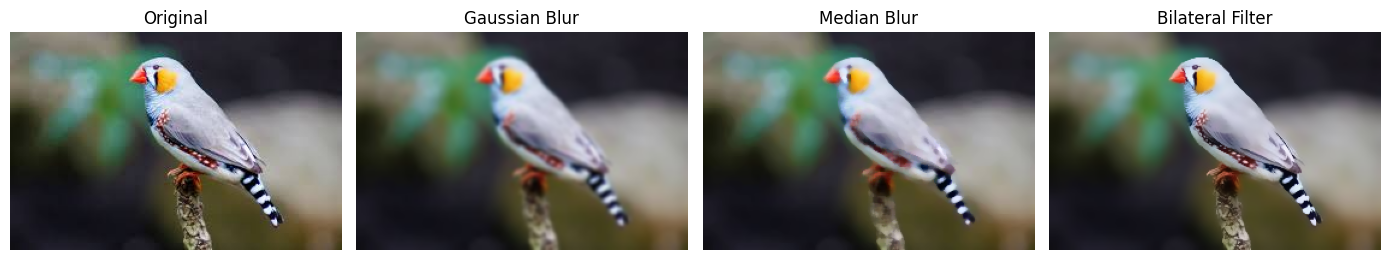

In [26]:
# Blurring and Smoothing Filters
# ── Gaussian Blur ─────────────────────────────────────────────────────────────
# Most commonly used. Reduces noise while preserving edges reasonably.
# ksize must be odd: (3,3), (5,5), (7,7) ...
gauss = cv2.GaussianBlur(img_bgr, ksize=(7, 7), sigmaX=0)

# ── Median Blur ───────────────────────────────────────────────────────────────
# Best for 'salt-and-pepper' noise. Replaces each pixel with the median
# of its neighbourhood — preserves edges better than Gaussian.
median = cv2.medianBlur(img_bgr, ksize=5)

# ── Bilateral Filter ─────────────────────────────────────────────────────────
# Smooths flat regions but keeps sharp edges. Slower than the others.
bilateral = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)

show(
    [cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
     for x in [img_bgr, gauss, median, bilateral]],
    ['Original', 'Gaussian Blur', 'Median Blur', 'Bilateral Filter'],
    figsize=(14, 4)
)

**Edge Detection**#

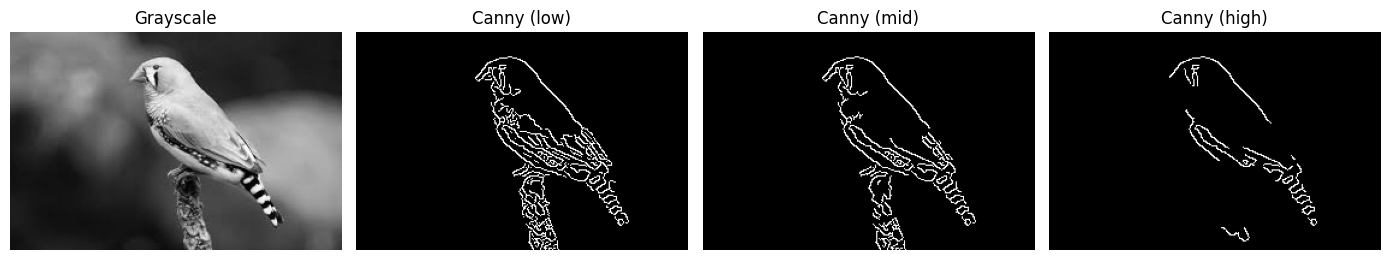

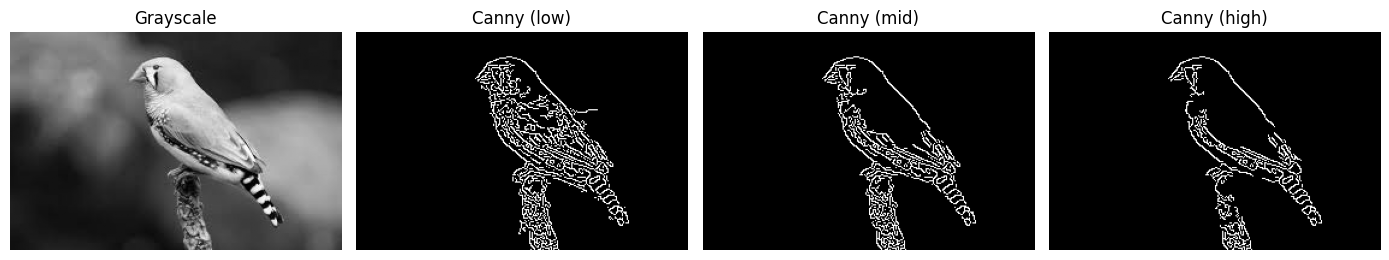

In [27]:
# Blured Images
# Always blur first — noise produces false edges
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Canny takes two thresholds:
#   threshold1  — below this: definitely NOT an edge
#   threshold2  — above this: definitely an edge
#   anything in between depends on connectivity
edges_low  = cv2.Canny(blurred, threshold1=30,  threshold2=100)
edges_mid  = cv2.Canny(blurred, threshold1=100, threshold2=200)
edges_high = cv2.Canny(blurred, threshold1=200, threshold2=400)

show(
    [gray, edges_low, edges_mid, edges_high],
    ['Grayscale', 'Canny (low)', 'Canny (mid)', 'Canny (high)'],
    cmap='gray',
    figsize=(14, 4)
)

# Gray Images
# Canny takes two thresholds:
#   threshold1  — below this: definitely NOT an edge
#   threshold2  — above this: definitely an edge
#   anything in between depends on connectivity
edges_low  = cv2.Canny(gray, threshold1=30,  threshold2=100)
edges_mid  = cv2.Canny(gray, threshold1=100, threshold2=200)
edges_high = cv2.Canny(gray, threshold1=200, threshold2=400)

show(
    [gray, edges_low, edges_mid, edges_high],
    ['Grayscale', 'Canny (low)', 'Canny (mid)', 'Canny (high)'],
    cmap='gray',
    figsize=(14, 4)
)

**Thresholding and Binary grey**#

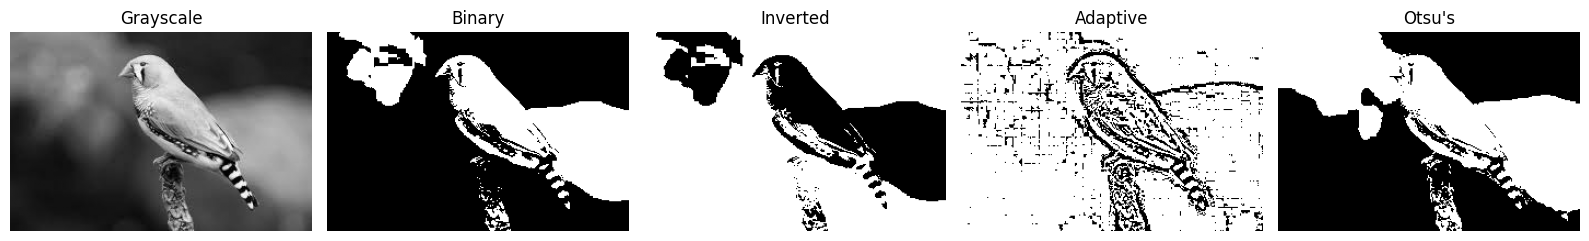

In [28]:
# ── Simple (global) threshold ─────────────────────────────────────────────────
# Every pixel > 127 becomes 255 (white); others become 0 (black)
_, thresh_binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
_, thresh_inv    = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)

# ── Adaptive threshold ────────────────────────────────────────────────────────
# Computes a local threshold per small region — handles uneven lighting
adapt = cv2.adaptiveThreshold(
    gray,
    maxValue=255,
    adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    thresholdType=cv2.THRESH_BINARY,
    blockSize=11,   # neighbourhood size (must be odd)
    C=2             # constant subtracted from mean
)

# ── Otsu's method ─────────────────────────────────────────────────────────────
# Automatically finds the best threshold from the histogram
_, otsu = cv2.threshold(gray, 0, 255,
                        cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show(
    [gray, thresh_binary, thresh_inv, adapt, otsu],
    ['Grayscale', 'Binary', 'Inverted', 'Adaptive', "Otsu's"],
    cmap='gray',
    figsize=(16, 4)
)

Found 51 contours


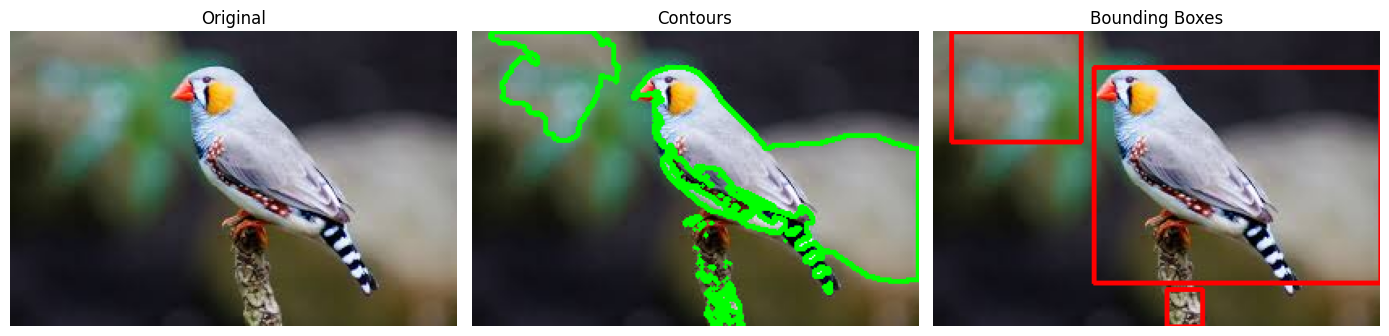

In [29]:
# Contours are curves along the boundary of a continuous region.
# Step 1: Get a binary image (threshold or edges)
_, bin_img = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Step 2: Find contours
# RETR_EXTERNAL — only outermost contours
# CHAIN_APPROX_SIMPLE — compress horizontal/vertical/diagonal segments
contours, hierarchy = cv2.findContours(
    bin_img,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
print(f"Found {len(contours)} contours")

# Step 3: Draw contours on the original image
contour_img = img_rgb.copy()
cv2.drawContours(contour_img,
                 contours,
                 contourIdx=-1,      # -1 = draw all
                 color=(0, 255, 0),  # green
                 thickness=2)

# Step 4: Bounding boxes around each contour
bbox_img = img_rgb.copy()
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    area = cv2.contourArea(cnt)
    if area > 50:   # ignore tiny noise contours
        cv2.rectangle(bbox_img, (x, y), (x+w, y+h), (255, 0, 0), 2)

show([img_rgb, contour_img, bbox_img],
     ['Original', 'Contours', 'Bounding Boxes'],
     figsize=(14, 4))

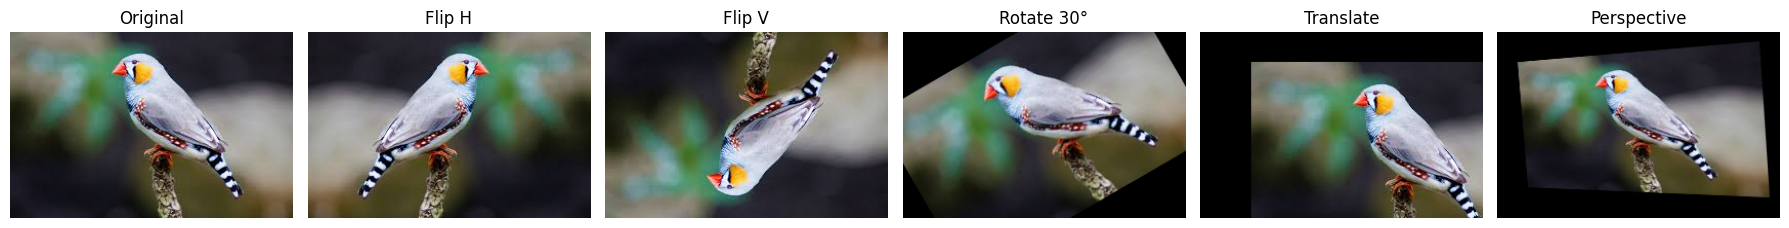

In [30]:
h, w = img_rgb.shape[:2]

# ── Flip ──────────────────────────────────────────────────────────────────────
flip_h = cv2.flip(img_rgb, flipCode=1)   # 1 = horizontal
flip_v = cv2.flip(img_rgb, flipCode=0)   # 0 = vertical

# ── Rotate ───────────────────────────────────────────────────────────────────
centre = (w // 2, h // 2)
M_rot = cv2.getRotationMatrix2D(center=centre, angle=30, scale=1.0)
rotated = cv2.warpAffine(img_rgb, M_rot, dsize=(w, h))

# ── Translate (shift) ────────────────────────────────────────────────────────
tx, ty = 50, 30   # shift right 50px, down 30px
M_trans = np.float32([[1, 0, tx],
                       [0, 1, ty]])
translated = cv2.warpAffine(img_rgb, M_trans, dsize=(w, h))

# ── Perspective warp ─────────────────────────────────────────────────────────
src_pts = np.float32([[0, 0], [w, 0], [0, h], [w, h]])
dst_pts = np.float32([[20, 30], [w-20, 10], [30, h-30], [w-10, h-20]])
M_persp = cv2.getPerspectiveTransform(src_pts, dst_pts)
warped  = cv2.warpPerspective(img_rgb, M_persp, (w, h))

show(
    [img_rgb, flip_h, flip_v, rotated, translated, warped],
    ['Original', 'Flip H', 'Flip V', 'Rotate 30°', 'Translate', 'Perspective'],
    figsize=(18, 4)
)

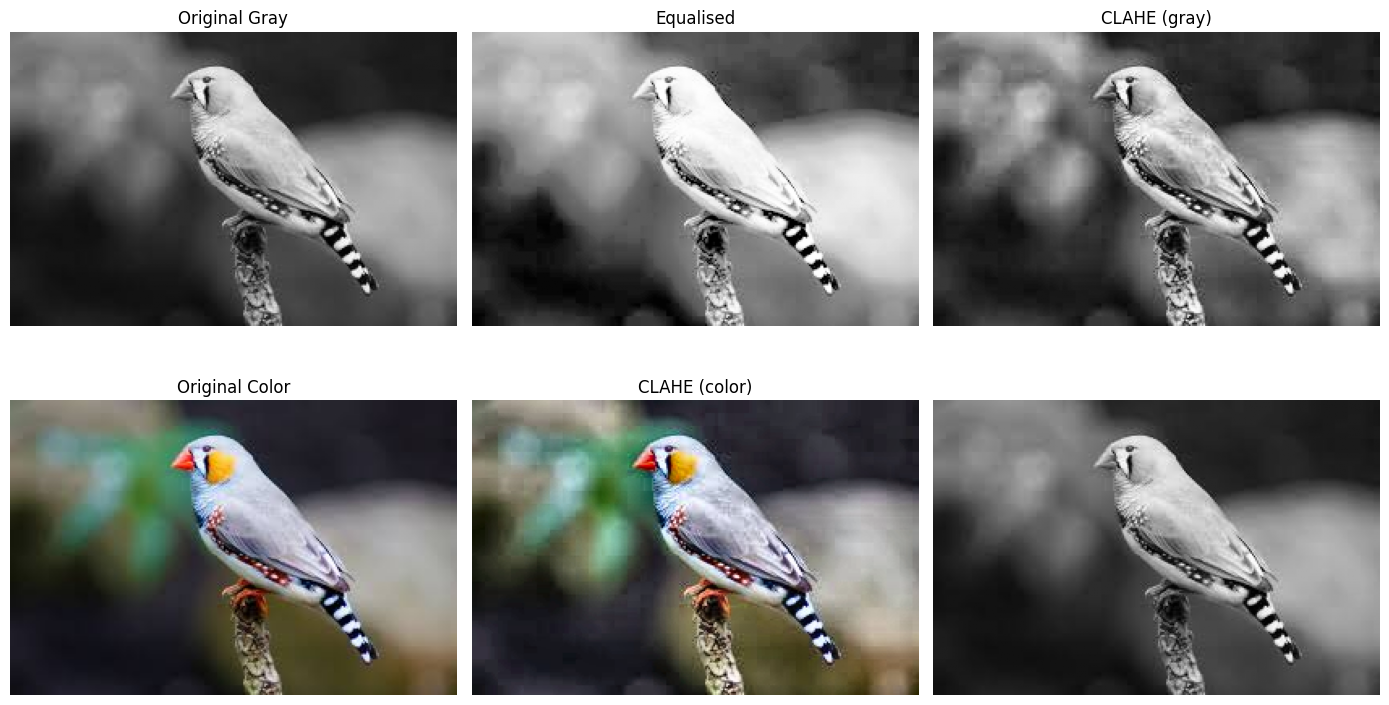

In [31]:
# Histogram equalisation improves contrast in low-contrast images
# by redistributing pixel intensity values across the full range.

# ── Standard equalisation (grayscale) ────────────────────────────────────────
eq_gray = cv2.equalizeHist(gray)

# ── CLAHE: Contrast Limited Adaptive Histogram Equalisation ──────────────────
# Works on small tiles independently — avoids over-amplifying noise.
# Apply to the L channel of LAB color space for color images.
clahe   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
eq_clahe = clahe.apply(gray)

# ── Color image CLAHE ────────────────────────────────────────────────────────
lab       = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
l, a, b_ch = cv2.split(lab)
l_eq      = clahe.apply(l)
lab_eq    = cv2.merge([l_eq, a, b_ch])
color_eq  = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, img, title, cm in zip(
    axes.flat,
    [gray, eq_gray, eq_clahe,
     img_rgb, cv2.cvtColor(color_eq, cv2.COLOR_BGR2RGB), gray],
    ['Original Gray', 'Equalised', 'CLAHE (gray)',
     'Original Color', 'CLAHE (color)', ''],
    ['gray','gray','gray', None, None, 'gray']
):
    ax.imshow(img, cmap=cm)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

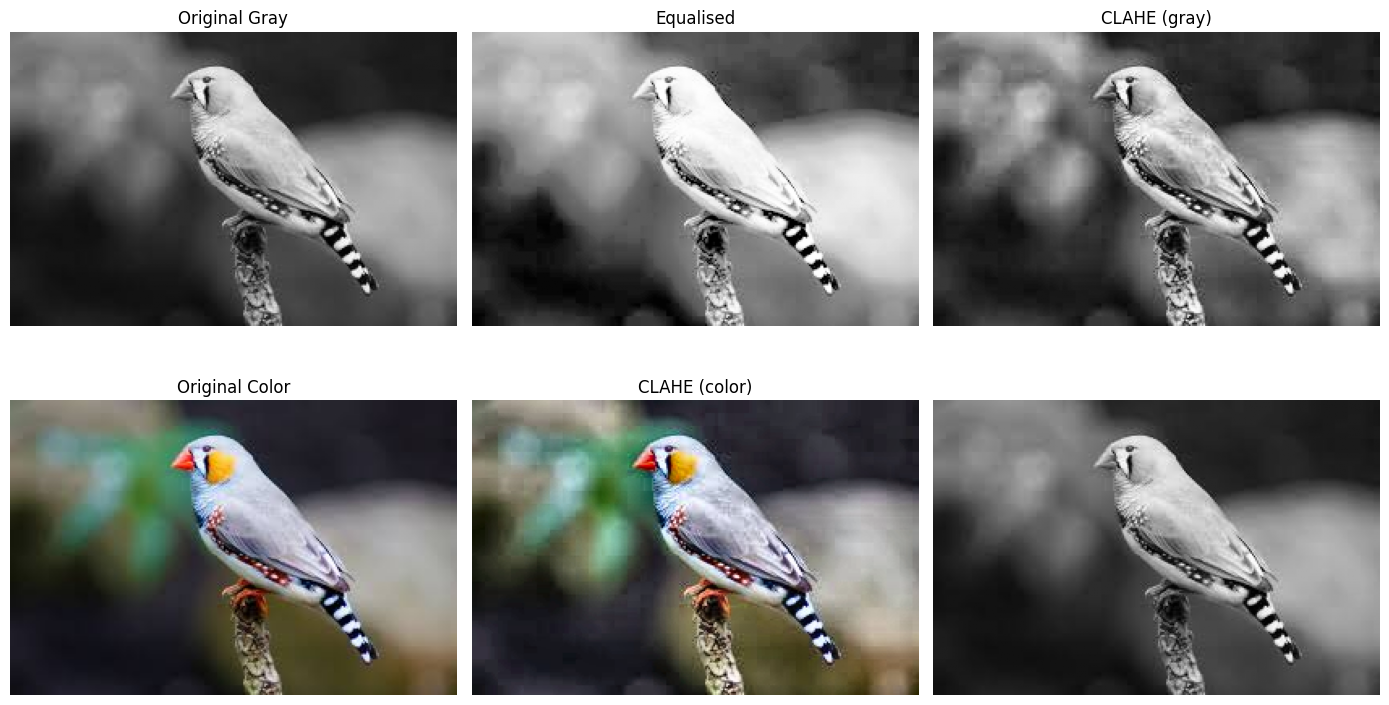

In [32]:
#Morphological Operations
# Histogram equalisation improves contrast in low-contrast images
# by redistributing pixel intensity values across the full range.

# ── Standard equalisation (grayscale) ────────────────────────────────────────
eq_gray = cv2.equalizeHist(gray)

# ── CLAHE: Contrast Limited Adaptive Histogram Equalisation ──────────────────
# Works on small tiles independently — avoids over-amplifying noise.
# Apply to the L channel of LAB color space for color images.
clahe   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
eq_clahe = clahe.apply(gray)

# ── Color image CLAHE ────────────────────────────────────────────────────────
lab       = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
l, a, b_ch = cv2.split(lab)
l_eq      = clahe.apply(l)
lab_eq    = cv2.merge([l_eq, a, b_ch])
color_eq  = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, img, title, cm in zip(
    axes.flat,
    [gray, eq_gray, eq_clahe,
     img_rgb, cv2.cvtColor(color_eq, cv2.COLOR_BGR2RGB), gray],
    ['Original Gray', 'Equalised', 'CLAHE (gray)',
     'Original Color', 'CLAHE (color)', ''],
    ['gray','gray','gray', None, None, 'gray']
):
    ax.imshow(img, cmap=cm)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
